# Phase 6 · Inspect profile coordinates and Explorer outputs

The plot in this notebook reads published profile coordinates and renders them separately by pathogen group. Coordinates are never pooled across groups unless the embedding release explicitly defines a shared feature space.

The current public human profile coordinates are retained as legacy baseline material. Native V4 embeddings will be written with their feature-profile version, selected input columns, seed, fit settings, and run ID.

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'pathogen_atlas_v4').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'pathogen_atlas_v4').is_dir():
    raise RuntimeError('Open this notebook from the V4 repository')
sys.path.insert(0, str(PROJECT_ROOT / 'notebooks'))
from _shared import configure_notebook, log_step
ROOT, LOG, LOG_PATH = configure_notebook('07_embeddings_explorer', 'explorer-inspection')
print('Project root:', ROOT, '| log:', LOG_PATH)

2026-11-02 11:25:25,000 INFO Notebook session started at 2026-11-02T11:25:25.000052+00:00


2026-11-02 11:25:25,000 INFO Project root: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/Pathogen Atlas/Pathogen Atlas/Pathogen Atlas Data Acquisition/version4


2026-11-02 11:25:25,000 INFO Run log: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/Pathogen Atlas/Pathogen Atlas/Pathogen Atlas Data Acquisition/version4/data/v4/logs/explorer-inspection/07_embeddings_explorer.log


Project root: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/Pathogen Atlas/Pathogen Atlas/Pathogen Atlas Data Acquisition/version4 | log: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/Pathogen Atlas/Pathogen Atlas/Pathogen Atlas Data Acquisition/version4/data/v4/logs/explorer-inspection/07_embeddings_explorer.log


## Step 1 · Load the current Explorer profile payload

In [2]:
import gzip, json, pandas as pd
from IPython.display import display
PAYLOAD_PATH = ROOT / 'sites/pathogen-atlas-explorer/explorer-data.json.gz'
payload = json.loads(gzip.open(PAYLOAD_PATH, 'rt', encoding='utf-8').read())
profiles = pd.DataFrame(payload['species'])
print('Payload:', PAYLOAD_PATH)
print('Groups:', payload['groups'], '| profiles:', len(profiles), '| coordinates_ready:', payload['coordinates_ready'])
display(profiles.groupby('organism_group').agg(profiles=('organism_id','nunique'),coordinates=('x','count')))
LOG.info('Loaded Explorer payload profiles=%d groups=%s', len(profiles), payload['groups'])

Payload: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/Pathogen Atlas/Pathogen Atlas/Pathogen Atlas Data Acquisition/version4/sites/pathogen-atlas-explorer/explorer-data.json.gz
Groups: ['bacteria', 'fungi', 'viruses'] | profiles: 2400 | coordinates_ready: True


,profiles,coordinates
organism_group,,
bacteria,1703,1703
fungi,440,440
viruses,257,257


2026-11-02 11:25:25,423 INFO Loaded Explorer payload profiles=2400 groups=['bacteria', 'fungi', 'viruses']


## Step 2 · Select one group and check coordinate completeness

In [3]:
GROUP_TO_PLOT = 'bacteria'
group = profiles.loc[profiles.organism_group.eq(GROUP_TO_PLOT)].copy()
group['x'] = pd.to_numeric(group.x, errors='coerce')
group['y'] = pd.to_numeric(group.y, errors='coerce')
plot_data = group.dropna(subset=['x','y'])
print('Selected group:', GROUP_TO_PLOT, '| profiles:', len(group), '| drawable:', len(plot_data))
assert len(plot_data) > 0, 'No coordinates available for selected group'
LOG.info('Coordinate check group=%s drawable=%d missing=%d', GROUP_TO_PLOT, len(plot_data), len(group)-len(plot_data))

2026-11-02 11:25:25,427 INFO Coordinate check group=bacteria drawable=1703 missing=0


Selected group: bacteria | profiles: 1703 | drawable: 1703


## Step 3 · Render a labeled SVG scatter plot

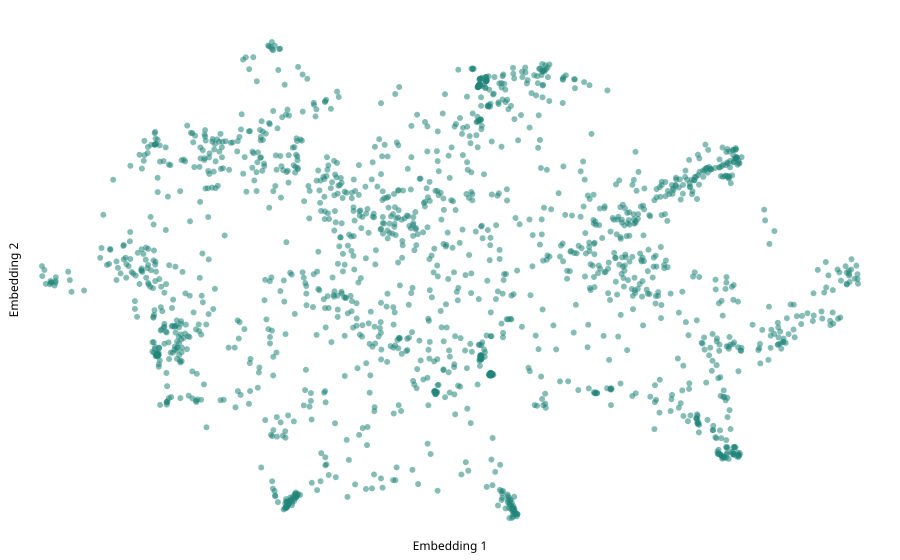

2026-11-02 11:25:25,449 INFO Rendered 1703 profile coordinates for bacteria


In [4]:
from html import escape
width, height, pad = 900, 560, 42
x0, x1 = plot_data.x.min(), plot_data.x.max(); y0, y1 = plot_data.y.min(), plot_data.y.max()
if x0 == x1: x1 = x0 + 1
if y0 == y1: y1 = y0 + 1
marks = []
for row in plot_data.itertuples(index=False):
    x = pad + (row.x-x0)/(x1-x0)*(width-2*pad)
    y = height-pad-(row.y-y0)/(y1-y0)*(height-2*pad)
    title = escape(str(row.accepted_name))
    marks.append(f'<circle cx="{x:.1f}" cy="{y:.1f}" r="3" fill="#21857b" fill-opacity=".55"><title>{title}</title></circle>')
svg = (f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">'
       f'<rect width="100%" height="100%" fill="white"/>{"".join(marks)}'
       f'<text x="{width/2}" y="{height-10}" text-anchor="middle" font-family="sans-serif">Embedding 1</text>'
       f'<text x="18" y="{height/2}" transform="rotate(-90 18 {height/2})" text-anchor="middle" font-family="sans-serif">Embedding 2</text></svg>')
from IPython.display import SVG, display
display(SVG(svg))
LOG.info('Rendered %d profile coordinates for %s', len(plot_data), GROUP_TO_PLOT)

## Step 4 · Record the plotted release and export

In [5]:
plot_record = {'source_payload': str(PAYLOAD_PATH.relative_to(ROOT)),
               'source_release': payload.get('schema_version'), 'group': GROUP_TO_PLOT,
               'profiles_plotted': len(plot_data), 'coordinates_missing': len(group)-len(plot_data),
               'provenance': payload.get('legacy_human_parity', {})}
PLOT_DIR = ROOT / 'data/v4/plots'
PLOT_DIR.mkdir(parents=True, exist_ok=True)
SVG_PATH = PLOT_DIR / f'{GROUP_TO_PLOT}-{payload.get("schema_version","explorer")}.svg'
SVG_PATH.write_text(svg, encoding='utf-8')
LOG.info('Saved plot %s; metadata=%s', SVG_PATH, plot_record)
display(plot_record)
print('SVG saved:', SVG_PATH)

2026-11-02 11:25:25,459 INFO Saved plot /Users/f.costa/Documents/Projects/Repositories/ACTIVE/Pathogen Atlas/Pathogen Atlas/Pathogen Atlas Data Acquisition/version4/data/v4/plots/bacteria-v4-explorer-human-parity-v1.svg; metadata={'source_payload': 'sites/pathogen-atlas-explorer/explorer-data.json.gz', 'source_release': 'v4-explorer-human-parity-v1', 'group': 'bacteria', 'profiles_plotted': 1703, 'coordinates_missing': 0, 'provenance': {'source_release': 'Pathogen Atlas V3', 'feature_profile_version': 'multi-domain-features-v3.2', 'profile_species': 2400, 'accepted_species_pmid_records': 35446, 'provenance_status': 'legacy_import', 'virus_pathogen_species': 257, 'virus_accepted_species_pmid_records': 5741}}


{'source_payload': 'sites/pathogen-atlas-explorer/explorer-data.json.gz',
 'source_release': 'v4-explorer-human-parity-v1',
 'group': 'bacteria',
 'profiles_plotted': 1703,
 'coordinates_missing': 0,
 'provenance': {'source_release': 'Pathogen Atlas V3',
  'feature_profile_version': 'multi-domain-features-v3.2',
  'profile_species': 2400,
  'accepted_species_pmid_records': 35446,
  'provenance_status': 'legacy_import',
  'virus_pathogen_species': 257,
  'virus_accepted_species_pmid_records': 5741}}

SVG saved: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/Pathogen Atlas/Pathogen Atlas/Pathogen Atlas Data Acquisition/version4/data/v4/plots/bacteria-v4-explorer-human-parity-v1.svg


## Step 5 · Native embedding handoff

In [6]:
EMBEDDING_RUN_READY = False
print('Native V4 embedding fitting is a separate pipeline stage. Record the resolved feature-profile hash, selected features, seed, software versions, and input run before fitting.')
LOG.info('Native embedding fit not started; baseline coordinates inspected')

2026-11-02 11:25:25,463 INFO Native embedding fit not started; baseline coordinates inspected


Native V4 embedding fitting is a separate pipeline stage. Record the resolved feature-profile hash, selected features, seed, software versions, and input run before fitting.
